In [17]:
import pandas as pd
import matplotlib.pyplot as plt

import os
os.chdir(r"C:\Users\steph\Downloads\lab1\e_comm_project")

In [18]:
df2 = pd.read_csv(r"C:\Users\steph\Downloads\lab1\e_comm_project\transactions_raw_data.csv")

In [19]:
df2

,transaction_id,customer_id,transaction_date,product_id,quantity,unit_price,payment_method,discount_applied,transaction_status,review_text
0,TX_0000003568,CUST0429,12/29/2024,WZ-802,30,448000,Credit Card,6.00,Completed,NaN
1,TX_0000001323,CUST0165,9/20/2025,LE-969,31,326000,E-wallet,7.00,Completed,NaN
2,TX_0000007976,CUST0969,9/19/2025,CR-562,22,326000,E-wallet,8.00,Completed,NaN
3,TX_0000002408,CUST0293,4/23/2025,BL-316,38,418000,Credit Card,42.00,Completed,NaN
4,TX_0000004435,CUST0537,8/28/2025,KL-203,3,15000,E-wallet,27.00,Completed,NaN
...,...,...,...,...,...,...,...,...,...,...
8194,TX_0000005735,CUST0695,9/24/2025,GA-889,31,132000,Debit Card,24.00,Completed,Very satisfied with this purchase
8195,TX_0000005192,CUST0627,12/23/2023,SM-851,40,377000,Cash,3.00,Completed,NaN
8196,TX_0000005391,CUST0655,10/10/2024,SV-067,2,83000,Debit Card,42.00,Completed,"Item damaged upon arrival, disappointed"
8197,TX_0000000861,CUST0107,11/16/2024,IR-720,23,112000,Debit Card,48.00,Completed,"Honest seller, item as described"


In [20]:
df2.info()

<class 'pandas.DataFrame'>
RangeIndex: 8199 entries, 0 to 8198
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   transaction_id      8199 non-null   str    
 1   customer_id         8199 non-null   str    
 2   transaction_date    8199 non-null   str    
 3   product_id          8199 non-null   str    
 4   quantity            8199 non-null   int64  
 5   unit_price          8199 non-null   int64  
 6   payment_method      8199 non-null   str    
 7   discount_applied    7773 non-null   float64
 8   transaction_status  8199 non-null   str    
 9   review_text         3283 non-null   str    
dtypes: float64(1), int64(2), str(7)
memory usage: 640.7 KB


Count dupes (no dupes)

In [21]:
df2.duplicated().sum()

np.int64(0)

Check to ensure there's no dupes

In [22]:
df2[df2.duplicated(keep = False)]

,transaction_id,customer_id,transaction_date,product_id,quantity,unit_price,payment_method,discount_applied,transaction_status,review_text


Check data types

In [23]:
df2.dtypes

transaction_id            str
customer_id               str
transaction_date          str
product_id                str
quantity                int64
unit_price              int64
payment_method            str
discount_applied      float64
transaction_status        str
review_text               str
dtype: object

Correlation check

In [24]:
df2[["quantity", "unit_price"]].corr()

,quantity,unit_price
quantity,1.00,0.12
unit_price,0.12,1.00


Unit price distribution huge spike in price as 95% are below 486,000 but top 1% reach up to 1 million. The graph below is also skewed heavily to the right by 3.47

In [25]:
pd.set_option("display.float_format", "{:,.2f}".format)

df2["unit_price"].describe(percentiles=[
    .01, .05, .10, .25, .50, .75, .90, .95, .99
])

count       8,199.00
mean      294,208.17
std       187,418.41
min           100.00
1%          8,000.00
5%         66,000.00
10%       109,000.00
25%       175,000.00
50%       283,000.00
75%       395,000.00
90%       462,000.00
95%       486,000.00
99%     1,082,000.00
max     2,000,000.00
Name: unit_price, dtype: float64

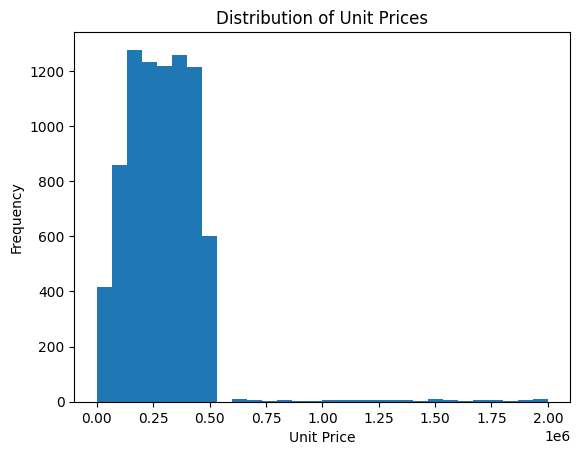

In [26]:
plt.hist(df2["unit_price"], bins=30)

plt.xlabel("Unit Price")
plt.ylabel("Frequency")
plt.title("Distribution of Unit Prices")

plt.show()

In [27]:
df2["unit_price"].skew()

np.float64(3.4735536165685894)

In [28]:
df2.shape

(8199, 10)

Null count

In [29]:
review_missing_percent = df2["review_text"].isna().mean() * 100
print("%",review_missing_percent)

% 59.95853152823515


In [ ]:
df2.to_csv("transactions_cleaned.csv", index=False)


: 